<a href="https://colab.research.google.com/github/Dimple7777/INSE6220/blob/main/02_model_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 – Model Training & Experimentation (Milestone 2)
**Project:** AI-Based Credit Card Fraud Detection (unsupervised anomaly detection) | **Course:** INSE 6450

**Main model:** Autoencoder. **Comparison model:** Isolation Forest.




## 1. Imports, settings and hardware summary

In [1]:
import os, sys, shutil, subprocess, time, json, random, itertools, copy, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from matplotlib.ticker import MaxNLocator
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, accuracy_score)

sns.set_theme(style="darkgrid")
plt.rcParams["figure.figsize"] = (7, 5)
pd.set_option("display.max_columns", None)

SEED = 42
QUICK_RUN = False
N_TRIALS = 2 if QUICK_RUN else 6
MAX_EPOCHS_TUNE = 3 if QUICK_RUN else 10
MAX_EPOCHS_FINAL = 5 if QUICK_RUN else 25
MAX_EPOCHS_ABL = 3 if QUICK_RUN else 15
PATIENCE = 2 if QUICK_RUN else 3
MIN_DELTA = 1e-5
EARLY_STOP_ON = "val_loss"
BATCH_SIZE = 2048
FLAG_RATE = 0.01
VAL_FRACTION = 0.20

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed()

for d in ("outputs/figures", "outputs/results", "outputs/models"):
    os.makedirs(d, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
try:
    import psutil
    ram_gb = psutil.virtual_memory().total / 1e9
except ImportError:
    ram_gb = float("nan")

HW = {
    "python": platform.python_version(),
    "pytorch": torch.__version__,
    "device": str(device),
    "cpu_cores": os.cpu_count(),
    "ram_gb": round(ram_gb, 1),
    "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else "none (CPU only)",
    "vram_gb": round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1) if device.type == "cuda" else 0.0,
}
for k, v in HW.items():
    print(f"{k:10s}: {v}")

python    : 3.13.16
pytorch   : 2.11.0+cpu
device    : cpu
cpu_cores : 2
ram_gb    : 13.6
gpu       : none (CPU only)
vram_gb   : 0.0


## 2. Download the dataset

In [2]:
try:
    import kagglehub
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
    import kagglehub

def download_data():
    """Download the dataset and copy the train/test CSVs into the current folder."""
    path = Path(kagglehub.dataset_download("kartik2112/fraud-detection"))
    for name in ("fraudTrain.csv", "fraudTest.csv"):
        shutil.copy(next(path.rglob(name)), name)

if not (os.path.exists("fraudTrain.csv") and os.path.exists("fraudTest.csv")):
    try:
        download_data()
    except Exception as e:
        print("Anonymous download failed:", e)
        print("Please log in to Kaggle below, then the download will retry.")
        kagglehub.login()
        download_data()

print("CSV files:", [f for f in os.listdir(".") if f.endswith(".csv")])

Using Colab cache for faster access to the 'fraud-detection' dataset.
CSV files: ['fraudTest.csv', 'fraudTrain.csv']


## 3. Load, clean and engineer features


In [3]:
train_df = pd.read_csv("fraudTrain.csv").drop(columns=["Unnamed: 0"], errors="ignore")
test_df = pd.read_csv("fraudTest.csv").drop(columns=["Unnamed: 0"], errors="ignore")

def clean(df):
    df = df.copy()
    df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])
    df["dob"] = pd.to_datetime(df["dob"])
    df = df.drop_duplicates(subset="trans_num").dropna()
    return df.sort_values("trans_date_trans_time").reset_index(drop=True)

def haversine_km(lat1, lon1, lat2, lon2):
    """Distance in km between customer home and merchant."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

def build_features(df):
    ts = df["trans_date_trans_time"]
    out = pd.DataFrame(index=df.index)
    out["hour"] = ts.dt.hour
    out["day_of_week"] = ts.dt.dayofweek
    out["month"] = ts.dt.month
    out["is_weekend"] = (out["day_of_week"] >= 5).astype(int)
    out["is_night"] = ((out["hour"] >= 22) | (out["hour"] <= 3)).astype(int)
    out["age"] = (ts - df["dob"]).dt.days / 365.25
    out["gender_male"] = (df["gender"] == "M").astype(int)
    out["log_amt"] = np.log1p(df["amt"])
    out["log_city_pop"] = np.log1p(df["city_pop"])
    out["distance_km"] = haversine_km(df["lat"], df["long"], df["merch_lat"], df["merch_long"])
    out["category"] = df["category"].values
    out["is_fraud"] = df["is_fraud"].values
    return out

def card_history_features(train_c, test_c):
    """Causal per-card features: use only transactions that happened BEFORE the current one."""
    tr = train_c.assign(_split="train", _rid=np.arange(len(train_c)))
    te = test_c.assign(_split="test", _rid=np.arange(len(test_c)))
    full = (pd.concat([tr, te], ignore_index=True)
              .sort_values("trans_date_trans_time", kind="stable").reset_index(drop=True))
    g = full.groupby("cc_num", sort=False)

    gap_hours = g["trans_date_trans_time"].diff().dt.total_seconds() / 3600
    n_prev = g.cumcount()
    past_mean = (g["amt"].cumsum() - full["amt"]) / n_prev.where(n_prev > 0)

    hist = pd.DataFrame({
        "log_hours_since_last": np.log1p(gap_hours.fillna(24.0)),
        "amt_vs_card_mean": (np.log1p(full["amt"]) - np.log1p(past_mean)).fillna(0.0),
        "_split": full["_split"], "_rid": full["_rid"],
    })
    parts = []
    for name in ("train", "test"):
        h = hist[hist["_split"] == name].sort_values("_rid").drop(columns=["_split", "_rid"])
        parts.append(h.reset_index(drop=True))
    return parts

train_clean, test_clean = clean(train_df), clean(test_df)
train_feat, test_feat = build_features(train_clean), build_features(test_clean)

train_hist, test_hist = card_history_features(train_clean, test_clean)
train_feat = pd.concat([train_feat, train_hist], axis=1)
test_feat = pd.concat([test_feat, test_hist], axis=1)

print("Train:", train_feat.shape, "| Test:", test_feat.shape)
train_feat.head()

Train: (1296675, 14) | Test: (555719, 14)


,hour,day_of_week,month,is_weekend,is_night,age,gender_male,log_amt,log_city_pop,distance_km,category,is_fraud,log_hours_since_last,amt_vs_card_mean
0,0,1,1,0,1,30.814511,0,1.786747,8.159375,78.597568,misc_net,0,3.218876,0.0
1,0,1,1,0,1,40.531143,0,4.684259,5.010635,30.212176,grocery_pos,0,3.218876,0.0
2,0,1,1,0,1,56.950034,1,5.398660,8.332068,108.206083,entertainment,0,3.218876,0.0
3,0,1,1,0,1,51.969884,1,3.828641,7.570443,95.673231,gas_transport,0,3.218876,0.0
4,0,1,1,0,1,32.763860,1,3.760269,4.605170,77.556744,misc_pos,0,3.218876,0.0


## 4. Train / validation / test split


In [4]:
split_idx = int(len(train_feat) * (1 - VAL_FRACTION))
tr_feat = train_feat.iloc[:split_idx].reset_index(drop=True)
va_feat = train_feat.iloc[split_idx:].reset_index(drop=True)
te_feat = test_feat.reset_index(drop=True)

ts_tr = train_clean["trans_date_trans_time"]
ts_te = test_clean["trans_date_trans_time"]
split_table = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "rows": [len(tr_feat), len(va_feat), len(te_feat)],
    "start": [ts_tr.iloc[0], ts_tr.iloc[split_idx], ts_te.iloc[0]],
    "end": [ts_tr.iloc[split_idx - 1], ts_tr.iloc[-1], ts_te.iloc[-1]],
    "fraud_count": [int(tr_feat["is_fraud"].sum()), int(va_feat["is_fraud"].sum()), int(te_feat["is_fraud"].sum())],
})
split_table["fraud_rate_%"] = (split_table["fraud_count"] / split_table["rows"] * 100).round(3)
split_table["start"] = split_table["start"].dt.date
split_table["end"] = split_table["end"].dt.date
split_table

,split,rows,start,end,fraud_count,fraud_rate_%
0,train,1037340,2019-01-01,2020-03-06,5968,0.575
1,validation,259335,2020-03-06,2020-06-21,1538,0.593
2,test,555719,2020-06-21,2020-12-31,2145,0.386


## 5. Encode and scale
One-hot encoding of `category` and standard scaling are **fit on the training split only** and then applied to validation and test (no leakage).

In [5]:
tr_enc = pd.get_dummies(tr_feat, columns=["category"], prefix="cat", dtype=int)
va_enc = pd.get_dummies(va_feat, columns=["category"], prefix="cat", dtype=int).reindex(columns=tr_enc.columns, fill_value=0)
te_enc = pd.get_dummies(te_feat, columns=["category"], prefix="cat", dtype=int).reindex(columns=tr_enc.columns, fill_value=0)

SCALE_COLS = ["hour", "day_of_week", "month", "age", "log_amt", "log_city_pop", "distance_km",
              "log_hours_since_last", "amt_vs_card_mean"]
scaler = StandardScaler().fit(tr_enc[SCALE_COLS])
for df_ in (tr_enc, va_enc, te_enc):
    df_[SCALE_COLS] = scaler.transform(df_[SCALE_COLS])

FEATURES = [c for c in tr_enc.columns if c != "is_fraud"]
X_tr, X_va, X_te = (d[FEATURES].to_numpy(np.float32) for d in (tr_enc, va_enc, te_enc))
y_tr, y_va, y_te = (d["is_fraud"].to_numpy(int) for d in (tr_enc, va_enc, te_enc))

print("Number of input features:", len(FEATURES))
print("X_train:", X_tr.shape, "| X_val:", X_va.shape, "| X_test:", X_te.shape)

Xva_t = torch.from_numpy(X_va).to(device)
Xte_t = torch.from_numpy(X_te).to(device)

Number of input features: 26
X_train: (1037340, 26) | X_val: (259335, 26) | X_test: (555719, 26)


## 6. Helper functions (autoencoder, training loop, metrics)

In [6]:
class AutoEncoder(nn.Module):
    """Fully connected autoencoder: input -> hidden layers -> bottleneck -> mirrored decoder -> input."""
    def __init__(self, n_in, hidden=(32,), bottleneck=8):
        super().__init__()
        enc_dims = [n_in, *hidden, bottleneck]
        dec_dims = [bottleneck, *reversed(hidden), n_in]
        def mlp(dims):
            layers = []
            for i in range(len(dims) - 1):
                layers.append(nn.Linear(dims[i], dims[i + 1]))
                if i < len(dims) - 2:
                    layers.append(nn.ReLU())
            return nn.Sequential(*layers)
        self.encoder, self.decoder = mlp(enc_dims), mlp(dec_dims)

    def forward(self, x):
        return self.decoder(self.encoder(x))


@torch.no_grad()
def recon_error(model, X, bs=65536):
    """Anomaly score = mean squared reconstruction error per transaction."""
    model.eval()
    out = []
    for i in range(0, len(X), bs):
        xb = X[i:i + bs]
        out.append(((model(xb) - xb) ** 2).mean(dim=1).cpu())
    return torch.cat(out).numpy()


def train_ae(X_train, X_val_t, y_val, cfg, max_epochs, patience=PATIENCE, trim=0.0, seed=SEED, verbose=False):
    """Train an autoencoder with early stopping (criterion: EARLY_STOP_ON, default validation loss).

    trim > 0 ignores the `trim` fraction of samples with the largest error in every batch
    (a label-free way to reduce the influence of fraud hidden in the training data).
    Returns (model, history DataFrame, info dict).
    """
    set_seed(seed)
    model = AutoEncoder(X_train.shape[1], cfg["hidden"], cfg["bottleneck"]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    Xt = torch.from_numpy(X_train).to(device)
    n = len(Xt)

    hist = {"epoch": [], "train_loss": [], "val_loss": [], "val_pr_auc": [], "epoch_time_s": []}
    best_score, best_state, best_epoch, wait = float("inf"), None, 0, 0
    t_start = time.time()

    for epoch in range(1, max_epochs + 1):
        model.train()
        t0 = time.time()
        perm = torch.randperm(n, device=device)
        running = torch.zeros((), device=device)
        for i in range(0, n, BATCH_SIZE):
            xb = Xt[perm[i:i + BATCH_SIZE]]
            err = ((model(xb) - xb) ** 2).mean(dim=1)
            if trim > 0:
                keep = max(1, int(len(err) * (1 - trim)))
                err = torch.topk(err, keep, largest=False).values
            loss = err.mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
            running += loss.detach() * len(xb)
        train_loss = running.item() / n

        val_scores = recon_error(model, X_val_t)
        val_loss = float(val_scores.mean())
        val_pr = average_precision_score(y_val, val_scores)   # labels used for MONITORING only

        for k, v in zip(hist, (epoch, train_loss, val_loss, val_pr, time.time() - t0)):
            hist[k].append(v)
        if verbose:
            print(f"epoch {epoch:2d} | train {train_loss:.4f} | val {val_loss:.4f} | val PR-AUC {val_pr:.4f}")

        stop_metric = val_loss if EARLY_STOP_ON == "val_loss" else -val_pr   # lower is better
        if stop_metric < best_score - MIN_DELTA:               # early stopping criterion
            best_score, best_epoch, wait = stop_metric, epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    info = {"epochs_run": epoch, "best_epoch": best_epoch, "train_time_s": time.time() - t_start,
            "n_params": sum(p.numel() for p in model.parameters())}
    return model, pd.DataFrame(hist), info


def evaluate(y, scores, thr=None, flag_rate=FLAG_RATE):
    """Task metrics. Default operating point: flag the top `flag_rate` of scores (alert budget)."""
    if thr is None:
        thr = np.quantile(scores, 1 - flag_rate)
    pred = (scores >= thr).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y, scores),
        "PR-AUC": average_precision_score(y, scores),
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "Macro-F1": f1_score(y, pred, average="macro", zero_division=0),
        "Alert rate": pred.mean(),
    }


def md_table(df, floatfmt=4):
    """Small helper that prints a DataFrame as a Markdown table (for the report)."""
    cols = list(df.columns)
    lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, row in df.iterrows():
        cells = []
        for v in row:
            if v is pd.NA or (isinstance(v, (float, np.floating)) and np.isnan(v)):
                cells.append("n/a")
            elif isinstance(v, (float, np.floating)):
                cells.append(f"{v:.{floatfmt}f}")
            else:
                cells.append(str(v))
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)

print("Helpers ready. Alert budget:", f"{FLAG_RATE:.0%}", "of transactions flagged")

Helpers ready. Alert budget: 1% of transactions flagged


## 7. Baselines: random scorer and Isolation Forest
- **Random scorer:** lower bound. Its PR-AUC equals the fraud rate.
- **Isolation Forest:** the alternative model family from Model Selection. It is unsupervised (labels not used for fitting). A small grid of 4 settings is compared on validation PR-AUC.

In [7]:
rng = np.random.default_rng(SEED)
rand_va, rand_te = rng.random(len(y_va)), rng.random(len(y_te))

if_grid = [{"n_estimators": 100, "max_samples": 256},  {"n_estimators": 300, "max_samples": 256},
           {"n_estimators": 100, "max_samples": 2048}, {"n_estimators": 300, "max_samples": 2048}]
if QUICK_RUN:
    if_grid = if_grid[:2]

if_rows, if_models = [], []
for cfg in if_grid:
    t0 = time.time()
    iso = IsolationForest(**cfg, contamination="auto", random_state=SEED, n_jobs=-1).fit(X_tr)
    fit_s = time.time() - t0
    s_va = -iso.score_samples(X_va)
    if_rows.append({**cfg, "val PR-AUC": average_precision_score(y_va, s_va),
                    "val ROC-AUC": roc_auc_score(y_va, s_va), "fit time (s)": fit_s})
    if_models.append(iso)

if_tuning = pd.DataFrame(if_rows)
best_if_i = int(if_tuning["val PR-AUC"].idxmax())
iso_best, if_cfg_best = if_models[best_if_i], if_grid[best_if_i]
if_fit_time = float(if_tuning.loc[best_if_i, "fit time (s)"])
print("Best Isolation Forest:", if_cfg_best)
if_tuning.round(4)

Best Isolation Forest: {'n_estimators': 100, 'max_samples': 256}


,n_estimators,max_samples,val PR-AUC,val ROC-AUC,fit time (s)
0,100,256,0.2180,0.9102,1.0509
1,300,256,0.1277,0.9129,5.0750
2,100,2048,0.1446,0.9014,1.7646
3,300,2048,0.1267,0.9101,6.6322


## 8. Hyperparameter tuning (autoencoder): random search
**Approach:** random search over 36 possible settings (hidden layers × bottleneck size × learning rate × weight decay). `N_TRIALS` settings are sampled and each is trained for at most `MAX_EPOCHS_TUNE` epochs with early stopping on the validation reconstruction loss. The setting with the best **validation PR-AUC** is selected (labels are used only for this selection, not to train weights). The test set is not touched.

In [8]:
space = {"hidden": [(16,), (32,), (64, 32)], "bottleneck": [4, 8, 16],
         "lr": [1e-3, 3e-3], "weight_decay": [0.0, 1e-5]}
all_cfgs = [dict(zip(space, vals)) for vals in itertools.product(*space.values())]
trials = random.Random(SEED).sample(all_cfgs, N_TRIALS)

tune_rows = []
for i, cfg in enumerate(trials, 1):
    model, hist_, info = train_ae(X_tr, Xva_t, y_va, cfg, max_epochs=MAX_EPOCHS_TUNE)
    s_va = recon_error(model, Xva_t)
    tune_rows.append({"trial": i, "hidden": str(cfg["hidden"]), "bottleneck": cfg["bottleneck"],
                      "lr": cfg["lr"], "weight_decay": cfg["weight_decay"],
                      "params": info["n_params"], "best_epoch": info["best_epoch"],
                      "val loss": float(hist_["val_loss"].min()),
                      "val PR-AUC": average_precision_score(y_va, s_va),
                      "val ROC-AUC": roc_auc_score(y_va, s_va), "time (s)": info["train_time_s"]})
    print(f"trial {i}/{N_TRIALS}: {cfg} -> val PR-AUC {tune_rows[-1]['val PR-AUC']:.4f}")

tuning_df = pd.DataFrame(tune_rows).sort_values("val PR-AUC", ascending=False).reset_index(drop=True)
best_cfg = trials[int(tuning_df.loc[0, "trial"]) - 1]
print("\nSelected configuration:", best_cfg)
tuning_df.round(4)

trial 1/6: {'hidden': (16,), 'bottleneck': 8, 'lr': 0.003, 'weight_decay': 1e-05} -> val PR-AUC 0.3423
trial 2/6: {'hidden': (16,), 'bottleneck': 4, 'lr': 0.001, 'weight_decay': 1e-05} -> val PR-AUC 0.0537
trial 3/6: {'hidden': (32,), 'bottleneck': 8, 'lr': 0.001, 'weight_decay': 1e-05} -> val PR-AUC 0.0870
trial 4/6: {'hidden': (32,), 'bottleneck': 4, 'lr': 0.003, 'weight_decay': 1e-05} -> val PR-AUC 0.0651
trial 5/6: {'hidden': (32,), 'bottleneck': 4, 'lr': 0.003, 'weight_decay': 0.0} -> val PR-AUC 0.0385
trial 6/6: {'hidden': (16,), 'bottleneck': 8, 'lr': 0.001, 'weight_decay': 0.0} -> val PR-AUC 0.3035

Selected configuration: {'hidden': (16,), 'bottleneck': 8, 'lr': 0.003, 'weight_decay': 1e-05}


,trial,hidden,bottleneck,lr,weight_decay,params,best_epoch,val loss,val PR-AUC,val ROC-AUC,time (s)
0,1,"(16,)",8,0.003,0.0,1154,10,0.0478,0.3423,0.6994,18.2836
1,6,"(16,)",8,0.001,0.0,1154,4,0.0521,0.3035,0.8156,12.6549
2,3,"(32,)",8,0.001,0.0,2274,10,0.0402,0.0870,0.7728,26.5999
3,4,"(32,)",4,0.003,0.0,2014,10,0.0896,0.0651,0.7980,20.5002
4,2,"(16,)",4,0.001,0.0,1022,10,0.1473,0.0537,0.8856,24.9946
5,5,"(32,)",4,0.003,0.0,2014,10,0.0928,0.0385,0.8044,21.4111


## 9. Final autoencoder and learning curves
The selected configuration is retrained with a longer epoch cap. Training stops when the validation loss has not improved by `MIN_DELTA` for `PATIENCE` epochs, and the best weights are restored.

epoch  1 | train 0.1195 | val 0.0524 | val PR-AUC 0.2476
epoch  2 | train 0.0518 | val 0.0490 | val PR-AUC 0.3462
epoch  3 | train 0.0489 | val 0.0484 | val PR-AUC 0.3131
epoch  4 | train 0.0487 | val 0.0483 | val PR-AUC 0.3200
epoch  5 | train 0.0487 | val 0.0484 | val PR-AUC 0.3312
epoch  6 | train 0.0487 | val 0.0483 | val PR-AUC 0.3191
epoch  7 | train 0.0486 | val 0.0479 | val PR-AUC 0.3358
epoch  8 | train 0.0483 | val 0.0479 | val PR-AUC 0.3153
epoch  9 | train 0.0483 | val 0.0479 | val PR-AUC 0.3439
epoch 10 | train 0.0482 | val 0.0478 | val PR-AUC 0.3423
epoch 11 | train 0.0482 | val 0.0478 | val PR-AUC 0.3257
epoch 12 | train 0.0482 | val 0.0478 | val PR-AUC 0.3322
epoch 13 | train 0.0482 | val 0.0478 | val PR-AUC 0.3279
epoch 14 | train 0.0482 | val 0.0478 | val PR-AUC 0.3193

Epochs run: 14 | best epoch: 11 | training time: 25.4 s | parameters: 1154


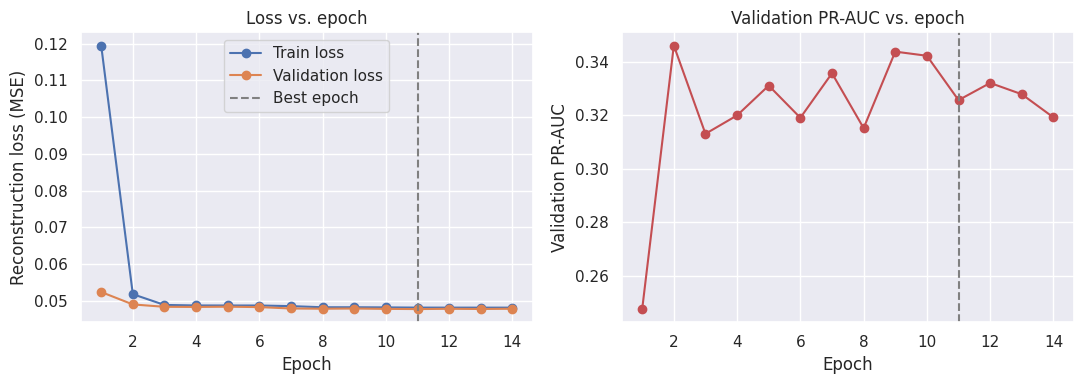

In [9]:
final_model, hist_df, final_info = train_ae(X_tr, Xva_t, y_va, best_cfg, max_epochs=MAX_EPOCHS_FINAL, verbose=True)
print("\nEpochs run:", final_info["epochs_run"], "| best epoch:", final_info["best_epoch"],
      "| training time: %.1f s" % final_info["train_time_s"], "| parameters:", final_info["n_params"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(hist_df["epoch"], hist_df["train_loss"], marker="o", label="Train loss")
axes[0].plot(hist_df["epoch"], hist_df["val_loss"], marker="o", label="Validation loss")
axes[0].axvline(final_info["best_epoch"], color="gray", ls="--", label="Best epoch")
axes[0].set(xlabel="Epoch", ylabel="Reconstruction loss (MSE)", title="Loss vs. epoch")
axes[0].legend()

axes[1].plot(hist_df["epoch"], hist_df["val_pr_auc"], marker="o", color="#c44e52")
axes[1].axvline(final_info["best_epoch"], color="gray", ls="--")
axes[1].set(xlabel="Epoch", ylabel="Validation PR-AUC", title="Validation PR-AUC vs. epoch")
for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()
plt.savefig("outputs/figures/learning_curves.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Ablations and class-imbalance mitigation (validation set)
All ablations use the selected configuration and the same seed, and are compared on **validation** PR-AUC (the test set is not used for any decision).

- **A. Baseline vs. final:** random scorer, Isolation Forest, autoencoder.
- **B. Model size:** small vs. medium vs. large autoencoder.
- **C. Key features on/off:** remove card-history features, amount features, or distance.
- **D. Class imbalance (only ~0.5% fraud):** the autoencoder is trained on all transactions, so a few frauds are mixed into the "normal" data. We compare (1) training on all data, (2) *trimmed loss* that ignores the 1% worst-reconstructed samples per batch (label-free re-weighting), and (3) training only on transactions known to be legitimate (uses labels to clean the training set, so it is semi-supervised and shown for comparison only).

In [10]:
abl_rows = []

def run_variant(group, name, X_train, X_val, cfg=best_cfg, trim=0.0, cols=None):
    """Train one ablation variant and log validation metrics."""
    Xv_t = torch.from_numpy(X_val).to(device) if cols is not None else Xva_t
    model, h, info = train_ae(X_train, Xv_t, y_va, cfg, max_epochs=MAX_EPOCHS_ABL, trim=trim)
    m = evaluate(y_va, recon_error(model, Xv_t))
    abl_rows.append({"group": group, "variant": name, "val PR-AUC": m["PR-AUC"], "val ROC-AUC": m["ROC-AUC"],
                     "val Recall@1%": m["Recall"], "val Precision@1%": m["Precision"],
                     "params": info["n_params"], "best_epoch": info["best_epoch"], "time (s)": info["train_time_s"]})
    print(f"[{group}] {name}: val PR-AUC {m['PR-AUC']:.4f}")

# A. baseline vs Selected model
iso_va = -iso_best.score_samples(X_va)
ae_va = recon_error(final_model, Xva_t)
for name, s in [("Random scorer", rand_va), ("Isolation Forest", iso_va), ("Autoencoder (final)", ae_va)]:
    m = evaluate(y_va, s)
    abl_rows.append({"group": "A. baseline vs final", "variant": name, "val PR-AUC": m["PR-AUC"],
                     "val ROC-AUC": m["ROC-AUC"], "val Recall@1%": m["Recall"], "val Precision@1%": m["Precision"],
                     "params": np.nan, "best_epoch": np.nan, "time (s)": np.nan})

# B. model size
for name, hidden, bott in [("small  (16-4-16)", (16,), 4), ("medium (32-8-32)", (32,), 8), ("large  (64-32-16-32-64)", (64, 32), 16)]:
    run_variant("B. model size", name, X_tr, X_va, cfg={**best_cfg, "hidden": hidden, "bottleneck": bott})

# C. key features on / off
feature_groups = {"without card-history features": ["log_hours_since_last", "amt_vs_card_mean"],
                  "without amount features": ["log_amt", "amt_vs_card_mean"],
                  "without distance_km": ["distance_km"]}
run_variant("C. features", "all features (final)", X_tr, X_va)
for name, drop in feature_groups.items():
    idx = [i for i, c in enumerate(FEATURES) if c not in drop]
    run_variant("C. features", name, X_tr[:, idx], X_va[:, idx], cols=idx)

# D. class-imbalance handling
run_variant("D. imbalance", "train on all data (final)", X_tr, X_va)
run_variant("D. imbalance", "trimmed loss (drop worst 1% per batch)", X_tr, X_va, trim=0.01)
run_variant("D. imbalance", "legitimate-only training (uses labels)", X_tr[y_tr == 0], X_va)

ablation_df = pd.DataFrame(abl_rows)
ablation_df.round(4)

[B. model size] small  (16-4-16): val PR-AUC 0.0472
[B. model size] medium (32-8-32): val PR-AUC 0.0941
[B. model size] large  (64-32-16-32-64): val PR-AUC 0.0951
[C. features] all features (final): val PR-AUC 0.3257
[C. features] without card-history features: val PR-AUC 0.2600
[C. features] without amount features: val PR-AUC 0.0221
[C. features] without distance_km: val PR-AUC 0.1006
[D. imbalance] train on all data (final): val PR-AUC 0.3257
[D. imbalance] trimmed loss (drop worst 1% per batch): val PR-AUC 0.3389
[D. imbalance] legitimate-only training (uses labels): val PR-AUC 0.3568


,group,variant,val PR-AUC,val ROC-AUC,val Recall@1%,val Precision@1%,params,best_epoch,time (s)
0,A. baseline vs final,Random scorer,0.0056,0.4857,0.0078,0.0046,NaN,NaN,NaN
1,A. baseline vs final,Isolation Forest,0.2180,0.9102,0.3700,0.2194,NaN,NaN,NaN
2,A. baseline vs final,Autoencoder (final),0.3257,0.6983,0.4337,0.2571,NaN,NaN,NaN
3,B. model size,small (16-4-16),0.0472,0.8919,0.0962,0.0571,1022.0,12.0,27.3660
4,B. model size,medium (32-8-32),0.0941,0.7651,0.2087,0.1237,2274.0,13.0,30.5624
5,B. model size,large (64-32-16-32-64),0.0951,0.6693,0.1073,0.0636,8682.0,14.0,170.6793
6,C. features,all features (final),0.3257,0.6983,0.4337,0.2571,1154.0,11.0,25.5584
7,C. features,without card-history features,0.2600,0.7797,0.3485,0.2066,1088.0,5.0,13.8473
8,C. features,without amount features,0.0221,0.6088,0.0819,0.0486,1088.0,9.0,20.2520
9,C. features,without distance_km,0.1006,0.7105,0.2399,0.1423,1121.0,15.0,27.0190


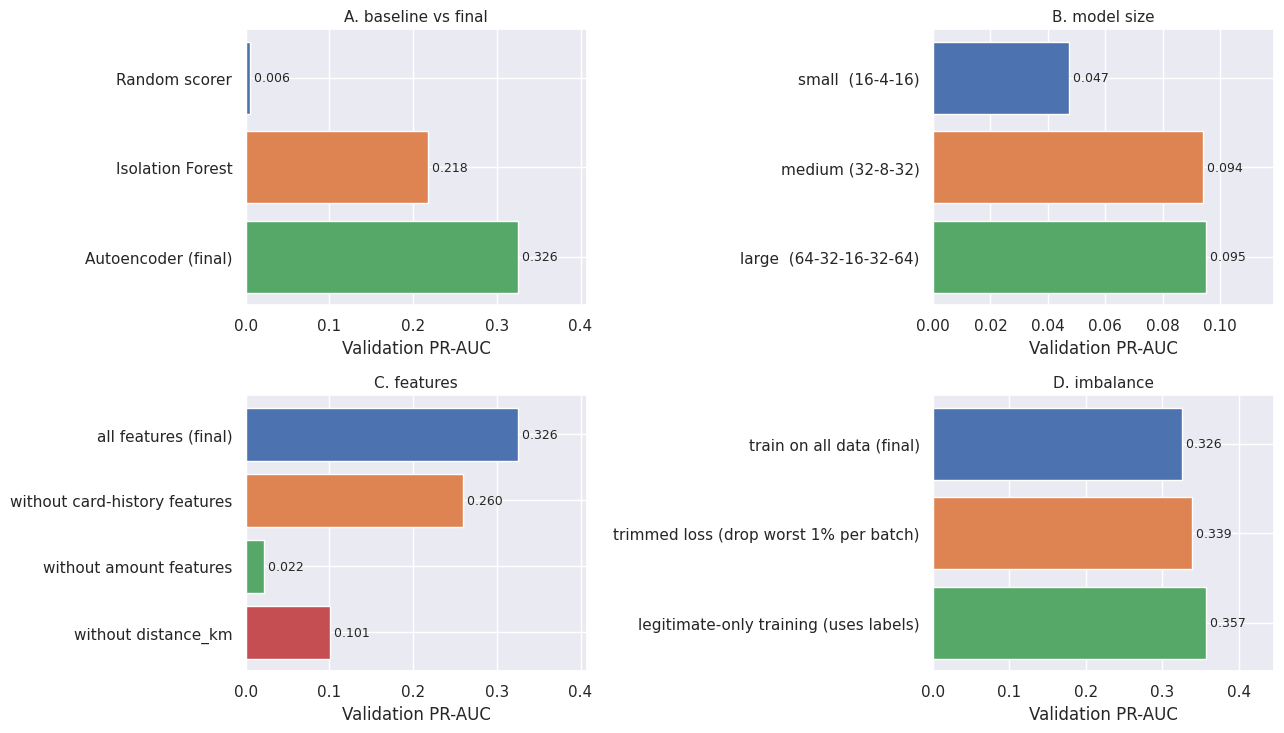

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
for ax, (grp, sub) in zip(axes.ravel(), ablation_df.groupby("group")):
    ax.barh(sub["variant"], sub["val PR-AUC"], color=sns.color_palette("deep")[: len(sub)])
    ax.invert_yaxis()
    ax.set_title(grp, fontsize=11)
    ax.set_xlabel("Validation PR-AUC")
    ax.set_xlim(0, max(0.05, sub["val PR-AUC"].max() * 1.25))
    for y_, v in enumerate(sub["val PR-AUC"]):
        ax.text(v, y_, f" {v:.3f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig("outputs/figures/ablation_summary.png", dpi=300, bbox_inches="tight")
plt.show()

### Seed stability
The final configuration is retrained with two more random seeds to see how much the result depends on initialisation.

In [12]:
seed_rows = [{"seed": SEED, "val PR-AUC": average_precision_score(y_va, ae_va),
              "test PR-AUC": average_precision_score(y_te, recon_error(final_model, Xte_t))}]
for s in [SEED + 1, SEED + 2]:
    m_, _, _ = train_ae(X_tr, Xva_t, y_va, best_cfg, max_epochs=MAX_EPOCHS_FINAL, seed=s)
    seed_rows.append({"seed": s, "val PR-AUC": average_precision_score(y_va, recon_error(m_, Xva_t)),
                      "test PR-AUC": average_precision_score(y_te, recon_error(m_, Xte_t))})
seed_df = pd.DataFrame(seed_rows)
print(seed_df.round(4).to_string(index=False))
print("\nmean +/- std  val PR-AUC: %.4f +/- %.4f | test PR-AUC: %.4f +/- %.4f" % (
    seed_df["val PR-AUC"].mean(), seed_df["val PR-AUC"].std(), seed_df["test PR-AUC"].mean(), seed_df["test PR-AUC"].std()))

 seed  val PR-AUC  test PR-AUC
   42      0.3257       0.2252
   43      0.2977       0.2142
   44      0.2893       0.2236

mean +/- std  val PR-AUC: 0.3042 +/- 0.0191 | test PR-AUC: 0.2210 +/- 0.0059


## 11. Task metrics on validation and test
Anomaly detection is evaluated as a binary problem (fraud = 1). The **operating point is the alert budget**: the top 1% of anomaly scores in each split are flagged for review.
Because fraud is only a fraction of a percent, accuracy is shown but is not informative; **PR-AUC, precision, recall and F1** are the key metrics.

In [13]:
iso_te = -iso_best.score_samples(X_te)
ae_te = recon_error(final_model, Xte_t)

rows = []
for model_name, s_va_, s_te_ in [("Random scorer", rand_va, rand_te),
                                 ("Isolation Forest", iso_va, iso_te),
                                 ("Autoencoder (final)", ae_va, ae_te)]:
    for split, y_, s_ in [("validation", y_va, s_va_), ("test", y_te, s_te_)]:
        rows.append({"model": model_name, "split": split, **evaluate(y_, s_)})
metrics_df = pd.DataFrame(rows)
metrics_df.round(4)

,model,split,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1,Macro-F1,Alert rate
0,Random scorer,validation,0.4857,0.0056,0.9842,0.0046,0.0078,0.0058,0.4989,0.01
1,Random scorer,test,0.5056,0.0040,0.9862,0.0052,0.0135,0.0075,0.5003,0.01
2,Isolation Forest,validation,0.9102,0.2180,0.9885,0.2194,0.3700,0.2754,0.6348,0.01
3,Isolation Forest,test,0.8967,0.1347,0.9889,0.1375,0.3562,0.1984,0.5964,0.01
4,Autoencoder (final),validation,0.6983,0.3257,0.9892,0.2571,0.4337,0.3228,0.6587,0.01
5,Autoencoder (final),test,0.6870,0.2252,0.9893,0.1582,0.4098,0.2282,0.6114,0.01


In [14]:
thr_val = np.quantile(ae_va, 1 - FLAG_RATE)

p_, r_, t_ = precision_recall_curve(y_va, ae_va)
thr_f1 = t_[np.argmax((2 * p_ * r_ / (p_ + r_ + 1e-12))[:-1])]

extra = pd.DataFrame([
    {"operating point": "top 1% of test scores (alert budget)", **evaluate(y_te, ae_te)},
    {"operating point": "fixed threshold = val 99th percentile", **evaluate(y_te, ae_te, thr=thr_val)},
    {"operating point": "fixed threshold = val F1-optimal", **evaluate(y_te, ae_te, thr=thr_f1)},
])
extra.round(4)

,operating point,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1,Macro-F1,Alert rate
0,top 1% of test scores (alert budget),0.687,0.2252,0.9893,0.1582,0.4098,0.2282,0.6114,0.0100
1,fixed threshold = val 99th percentile,0.687,0.2252,0.9905,0.1770,0.4000,0.2454,0.6203,0.0087
2,fixed threshold = val F1-optimal,0.687,0.2252,0.9954,0.3703,0.2802,0.3190,0.6583,0.0029


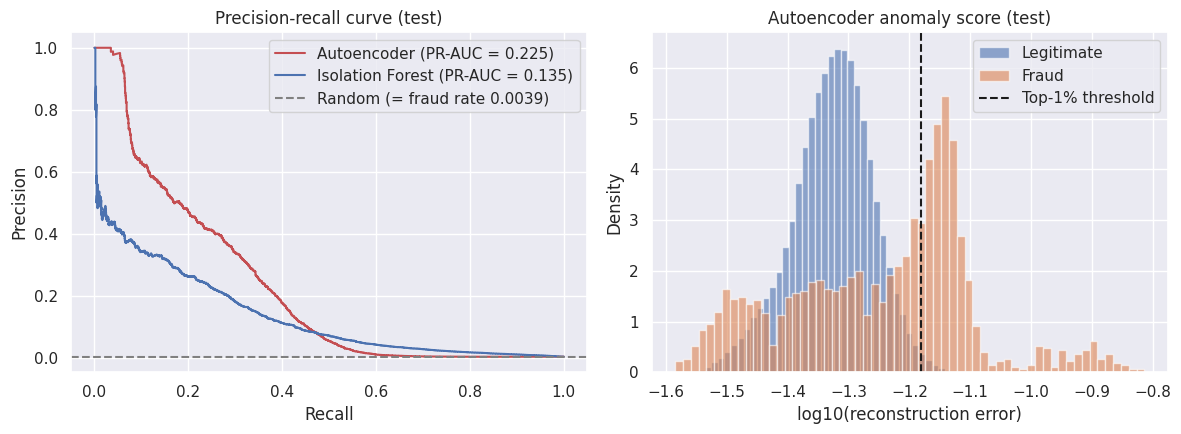

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, s, c in [("Autoencoder", ae_te, "#c44e52"), ("Isolation Forest", iso_te, "#4c72b0")]:
    p, r, _ = precision_recall_curve(y_te, s)
    axes[0].plot(r, p, label=f"{name} (PR-AUC = {average_precision_score(y_te, s):.3f})", color=c)
axes[0].axhline(y_te.mean(), color="gray", ls="--", label=f"Random (= fraud rate {y_te.mean():.4f})")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve (test)")
axes[0].legend()

axes[1].hist(np.log10(ae_te[y_te == 0] + 1e-9), bins=60, alpha=0.6, density=True, label="Legitimate")
axes[1].hist(np.log10(ae_te[y_te == 1] + 1e-9), bins=60, alpha=0.6, density=True, label="Fraud")
axes[1].axvline(np.log10(np.quantile(ae_te, 1 - FLAG_RATE)), color="k", ls="--", label="Top-1% threshold")
axes[1].set(xlabel="log10(reconstruction error)", ylabel="Density", title="Autoencoder anomaly score (test)")
axes[1].legend()
plt.tight_layout()
plt.savefig("outputs/figures/test_pr_curve_and_scores.png", dpi=300, bbox_inches="tight")
plt.show()

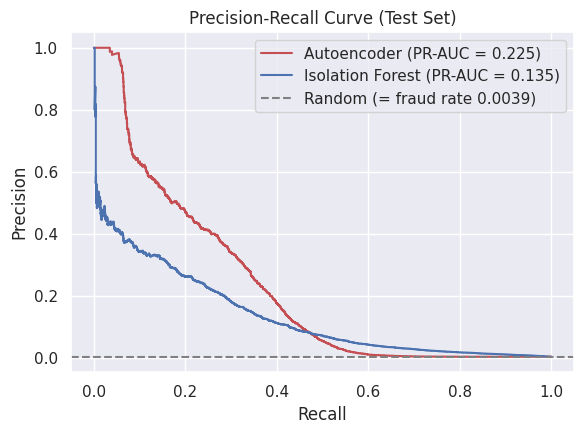

In [16]:
fig, ax = plt.subplots(figsize=(6, 4.5))

for name, s, c in [
    ("Autoencoder", ae_te, "#c44e52"),
    ("Isolation Forest", iso_te, "#4c72b0")
]:
    p, r, _ = precision_recall_curve(y_te, s)
    ax.plot(
        r, p,
        label=f"{name} (PR-AUC = {average_precision_score(y_te, s):.3f})",
        color=c
    )

ax.axhline(
    y_te.mean(),
    color="gray",
    linestyle="--",
    label=f"Random (= fraud rate {y_te.mean():.4f})"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve (Test Set)")
ax.legend(loc="best")

plt.tight_layout()
plt.savefig(
    "outputs/figures/test_pr_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [17]:
final_model.eval()
with torch.no_grad():
    top_idx = np.argsort(-ae_te)[:5]
    xb = Xte_t[top_idx]
    feat_err = ((final_model(xb) - xb) ** 2).cpu().numpy()
for rank, (i, e) in enumerate(zip(top_idx, feat_err), 1):
    top3 = np.argsort(-e)[:3]
    share = e[top3] / e.sum()
    print(f"#{rank} score={ae_te[i]:.2f} fraud={bool(y_te[i])} | main drivers: " +
          ", ".join(f"{FEATURES[j]} ({s:.0%})" for j, s in zip(top3, share)))

#1 score=0.15 fraud=True | main drivers: log_amt (30%), cat_shopping_net (25%), amt_vs_card_mean (25%)
#2 score=0.15 fraud=True | main drivers: cat_misc_net (28%), log_amt (26%), amt_vs_card_mean (23%)
#3 score=0.15 fraud=True | main drivers: amt_vs_card_mean (30%), log_amt (28%), cat_grocery_pos (24%)
#4 score=0.15 fraud=True | main drivers: cat_shopping_pos (27%), log_amt (27%), amt_vs_card_mean (22%)
#5 score=0.14 fraud=True | main drivers: log_amt (29%), cat_shopping_pos (28%), amt_vs_card_mean (24%)


## 12. Efficiency metrics (training and inference)
Inference is timed on **CPU** (a conservative proxy for an edge / small server): batch throughput on 100,000 transactions and single-transaction latency (p50 / p95 over repeated calls).

In [18]:
import joblib

def latency_ms(fn, n_calls):
    times = []
    for _ in range(n_calls):
        t0 = time.perf_counter(); fn(); times.append((time.perf_counter() - t0) * 1000)
    return np.percentile(times, 50), np.percentile(times, 95)

# ---- Autoencoder (CPU copy)
ae_cpu = copy.deepcopy(final_model).cpu().eval()
Xb = torch.from_numpy(X_te[:100000])
t0 = time.perf_counter(); recon_error(ae_cpu, Xb); ae_thru = len(Xb) / (time.perf_counter() - t0)
singles = [torch.from_numpy(X_te[i:i + 1]) for i in range(300)]
it = iter(singles * 2)
ae_p50, ae_p95 = latency_ms(lambda: recon_error(ae_cpu, next(it)), 300)
torch.save(final_model.state_dict(), "outputs/models/autoencoder.pt")
ae_size_kb = os.path.getsize("outputs/models/autoencoder.pt") / 1024

# ---- Isolation Forest
t0 = time.perf_counter(); iso_best.score_samples(X_te[:100000]); if_thru = 100000 / (time.perf_counter() - t0)
iso_best.set_params(n_jobs=1)                      # single-transaction latency: one thread, no pool overhead
it2 = iter(range(10**6))
if_p50, if_p95 = latency_ms(lambda: iso_best.score_samples(X_te[next(it2) % 1000:][:1]), 100)
joblib.dump(iso_best, "outputs/models/isolation_forest.joblib")
if_size_kb = os.path.getsize("outputs/models/isolation_forest.joblib") / 1024

efficiency_df = pd.DataFrame([
    {"model": "Autoencoder", "parameters": final_info["n_params"], "model size (KB)": ae_size_kb,
     "training time (s)": final_info["train_time_s"], "epochs run": final_info["epochs_run"],
     "CPU throughput (txn/s)": ae_thru, "latency p50 (ms)": ae_p50, "latency p95 (ms)": ae_p95},
    {"model": "Isolation Forest", "parameters": np.nan, "model size (KB)": if_size_kb,
     "training time (s)": if_fit_time, "epochs run": np.nan,
     "CPU throughput (txn/s)": if_thru, "latency p50 (ms)": if_p50, "latency p95 (ms)": if_p95},
])
for c in ["parameters", "epochs run", "CPU throughput (txn/s)"]:
    efficiency_df[c] = efficiency_df[c].round(0).astype("Int64")     # whole numbers, n/a where not applicable
efficiency_df.round(3)

,model,parameters,model size (KB),training time (s),epochs run,CPU throughput (txn/s),latency p50 (ms),latency p95 (ms)
0,Autoencoder,1154,8.067,25.367,14,4539633,0.180,0.274
1,Isolation Forest,<NA>,1304.419,1.051,<NA>,179763,7.496,9.594


## 13. Save results, model and preprocessing settings

In [19]:
metrics_df.to_csv("outputs/results/metrics_summary.csv", index=False)
extra.to_csv("outputs/results/operating_points_test.csv", index=False)
tuning_df.to_csv("outputs/results/autoencoder_tuning.csv", index=False)
if_tuning.to_csv("outputs/results/isolation_forest_tuning.csv", index=False)
ablation_df.to_csv("outputs/results/ablations.csv", index=False)
hist_df.to_csv("outputs/results/learning_curve.csv", index=False)
efficiency_df.to_csv("outputs/results/efficiency.csv", index=False)
split_table.to_csv("outputs/results/split_summary.csv", index=False)

with open("outputs/models/preprocessing.json", "w") as f:
    json.dump({"features": FEATURES, "scaled_columns": SCALE_COLS,
               "scaler_mean": dict(zip(SCALE_COLS, scaler.mean_.tolist())),
               "scaler_scale": dict(zip(SCALE_COLS, scaler.scale_.tolist())),
               "autoencoder_config": {**best_cfg, "hidden": list(best_cfg["hidden"])},
               "threshold_val_p99": float(thr_val)}, f, indent=2)
print(sorted(os.listdir("outputs/results")), sorted(os.listdir("outputs/models")))

['ablations.csv', 'autoencoder_tuning.csv', 'efficiency.csv', 'isolation_forest_tuning.csv', 'learning_curve.csv', 'metrics_summary.csv', 'operating_points_test.csv', 'split_summary.csv'] ['autoencoder.pt', 'isolation_forest.joblib', 'preprocessing.json']


## 14. Environment note
Library versions used for this run (for reproducibility).

In [20]:
import sklearn
print("Python", HW["python"], "| PyTorch", torch.__version__, "| scikit-learn", sklearn.__version__,
      "| pandas", pd.__version__, "| numpy", np.__version__)
print("Random seed:", SEED)

Python 3.13.16 | PyTorch 2.11.0+cpu | scikit-learn 1.6.1 | pandas 2.2.3 | numpy 2.1.3
Random seed: 42


In [21]:
shutil.make_archive("outputs", "zip", "outputs")
try:
    from google.colab import files
    files.download("outputs.zip")
except ImportError:
    print("Not running in Colab - everything is in the outputs/ folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
   !pip -q install onnx onnxruntime onnxscript

In [23]:
# =====================================================================
# Section 3 - Computational efficiency (replaces the old efficiency cell)
# Paste as ONE cell after section 12 of 02_model_training.ipynb and run.
# Uses the notebook's own objects: final_model, best_cfg, train_ae,
# X_tr, X_te, Xva_t, y_va, y_te, iso_best, if_cfg_best, recon_error,
# evaluate, BATCH_SIZE, SEED, device.
# In Colab, run this once first:  !pip -q install onnx onnxruntime onnxscript
# =====================================================================
import os, time, json, copy, threading, platform, subprocess
import numpy as np, pandas as pd, psutil, torch, torch.nn as nn, joblib
from sklearn.ensemble import IsolationForest

assert BATCH_SIZE == 2048, "BATCH_SIZE was changed by the old cell - reset it to 2048 and rerun section 1"
os.makedirs("outputs/models", exist_ok=True); os.makedirs("outputs/results", exist_ok=True)
proc = psutil.Process(os.getpid())
rss_mb = lambda: proc.memory_info().rss / 2**20

class PeakRSS:
    """Samples process RSS every 10 ms in a background thread; reports peak above the starting level."""
    def __enter__(self):
        self.base = self.peak = rss_mb(); self._run = True
        def loop():
            while self._run:
                self.peak = max(self.peak, rss_mb()); time.sleep(0.01)
        self._t = threading.Thread(target=loop, daemon=True); self._t.start(); return self
    def __exit__(self, *a):
        self._run = False; self._t.join(); self.peak = max(self.peak, rss_mb())
    @property
    def delta(self): return self.peak - self.base

def lat_ms(fn, n=1000, warm=50):
    for _ in range(warm): fn(0)
    t = []
    for i in range(n):
        t0 = time.perf_counter(); fn(i); t.append((time.perf_counter() - t0) * 1000)
    return np.percentile(t, [50, 90, 95])

# ---------------- hardware ----------------
try:
    cpu_name = subprocess.check_output("lscpu | grep 'Model name'", shell=True, text=True).split(":", 1)[1].strip()
except Exception:
    cpu_name = platform.processor() or platform.machine()
hw = {"CPU": cpu_name, "logical cores": os.cpu_count(),
      "RAM (GB)": round(psutil.virtual_memory().total / 1e9, 1),
      "GPU": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU only)",
      "PyTorch": torch.__version__, "torch threads": torch.get_num_threads()}
print("Hardware:", hw)

# ---------------- model complexity (read from the trained model) ----------------
linears = [m for m in final_model.modules() if isinstance(m, nn.Linear)]
arch = [linears[0].in_features] + [m.out_features for m in linears]
n_params = sum(p.numel() for p in final_model.parameters())
flops_fwd = sum(2 * m.in_features * m.out_features for m in linears)   # multiply + add per weight
print(f"Architecture {'-'.join(map(str, arch))} | params {n_params} | forward FLOPs/txn {flops_fwd}")

# ---------------- training efficiency (retrain with the same seed, sampling RAM) ----------------
with PeakRSS() as m_ae:
    t0 = time.perf_counter()
    ae_re, hist_re, info_re = train_ae(X_tr, Xva_t, y_va, best_cfg, max_epochs=MAX_EPOCHS_FINAL)
    ae_train_s = time.perf_counter() - t0
epochs = info_re["epochs_run"]
steps = int(np.ceil(len(X_tr) / BATCH_SIZE)) * epochs
peak_vram = torch.cuda.max_memory_allocated() / 2**20 if torch.cuda.is_available() else float("nan")

with PeakRSS() as m_if:
    t0 = time.perf_counter()
    iso_re = IsolationForest(**if_cfg_best, contamination="auto", random_state=SEED, n_jobs=-1).fit(X_tr)
    if_train_s = time.perf_counter() - t0

train_df = pd.DataFrame([
    {"model": "Autoencoder", "train rows": len(X_tr), "batch size": BATCH_SIZE, "epochs (best)": f"{epochs} ({info_re['best_epoch']})",
     "total time (s)": ae_train_s, "time/epoch (s)": ae_train_s / epochs, "steps/s": steps / ae_train_s,
     "peak RAM above baseline (MB)": m_ae.delta, "peak VRAM (MB)": peak_vram,
     "train GFLOPs (total, ~3x fwd)": 3 * flops_fwd * len(X_tr) * epochs / 1e9},
    {"model": "Isolation Forest", "train rows": len(X_tr), "batch size": "n/a", "epochs (best)": "n/a",
     "total time (s)": if_train_s, "time/epoch (s)": np.nan, "steps/s": np.nan,
     "peak RAM above baseline (MB)": m_if.delta, "peak VRAM (MB)": np.nan, "train GFLOPs (total, ~3x fwd)": np.nan},
])
print("\nTRAINING"); display(train_df.round(3))

# ---------------- inference variants ----------------
ae_cpu = copy.deepcopy(final_model).cpu().eval()
torch.save(ae_cpu.state_dict(), "outputs/models/autoencoder.pt")
X = np.ascontiguousarray(X_te, dtype=np.float32)

def torch_predict(model):
    def f(a):
        with torch.no_grad():
            return model(torch.from_numpy(a)).numpy()
    return f

variants = {"PyTorch FP32": (torch_predict(ae_cpu), "outputs/models/autoencoder.pt")}

try:   # PyTorch dynamic INT8 quantization of the Linear layers
    from torch.ao.quantization import quantize_dynamic as tq
    ae_q = tq(copy.deepcopy(ae_cpu), {nn.Linear}, dtype=torch.qint8).eval()
    torch.save(ae_q.state_dict(), "outputs/models/autoencoder_int8.pt")
    variants["PyTorch INT8 (dynamic)"] = (torch_predict(ae_q), "outputs/models/autoencoder_int8.pt")
except Exception as e:
    print("PyTorch INT8 skipped:", repr(e)[:200])

try:   # ONNX Runtime FP32 and INT8
    import onnxruntime as ort
    from onnxruntime.quantization import quantize_dynamic, QuantType
    kw = dict(input_names=["x"], output_names=["r"], dynamic_axes={"x": {0: "n"}, "r": {0: "n"}})
    try:
        torch.onnx.export(ae_cpu, torch.from_numpy(X[:1]), "outputs/models/autoencoder.onnx", dynamo=False, **kw)
    except TypeError:
        torch.onnx.export(ae_cpu, torch.from_numpy(X[:1]), "outputs/models/autoencoder.onnx", **kw)
    quantize_dynamic("outputs/models/autoencoder.onnx", "outputs/models/autoencoder_int8.onnx", weight_type=QuantType.QInt8)
    def ort_predict(path):
        s = ort.InferenceSession(path, providers=["CPUExecutionProvider"])
        return lambda a: s.run(None, {"x": a})[0]
    variants["ONNX Runtime FP32"] = (ort_predict("outputs/models/autoencoder.onnx"), "outputs/models/autoencoder.onnx")
    variants["ONNX Runtime INT8"] = (ort_predict("outputs/models/autoencoder_int8.onnx"), "outputs/models/autoencoder_int8.onnx")
except Exception as e:
    print("ONNX skipped (run: !pip -q install onnx onnxruntime onnxscript):", repr(e)[:200])

rows = []
for name, (pred, path) in variants.items():
    p50, p90, p95 = lat_ms(lambda i, pred=pred: pred(X[i % 1000: i % 1000 + 1]))
    pred(X[:BATCH_SIZE]); t0 = time.perf_counter(); pred(X[:BATCH_SIZE]); b_ms = (time.perf_counter() - t0) * 1000
    with PeakRSS() as m:
        t0 = time.perf_counter()
        scores = np.concatenate([((pred(X[i:i + 65536]) - X[i:i + 65536]) ** 2).mean(axis=1) for i in range(0, len(X), 65536)])
        full_s = time.perf_counter() - t0
    met = evaluate(y_te, scores)
    rows.append({"variant": name, "size (KB)": os.path.getsize(path) / 1024,
                 "p50 (ms)": p50, "p90 (ms)": p90, "p95 (ms)": p95, f"batch {BATCH_SIZE} (ms)": b_ms,
                 "throughput (txn/s)": len(X) / full_s, "inference RAM above baseline (MB)": m.delta,
                 "test PR-AUC": met["PR-AUC"], "test Recall@1%": met["Recall"]})

# Isolation Forest baseline (same protocol, single thread for single-txn latency)
joblib.dump(iso_best, "outputs/models/isolation_forest.joblib")
iso_best.set_params(n_jobs=1)
p50, p90, p95 = lat_ms(lambda i: iso_best.score_samples(X[i % 1000: i % 1000 + 1]), n=200, warm=10)
t0 = time.perf_counter(); iso_best.score_samples(X[:BATCH_SIZE]); b_ms = (time.perf_counter() - t0) * 1000
iso_best.set_params(n_jobs=-1)
with PeakRSS() as m:
    t0 = time.perf_counter(); s_if = -iso_best.score_samples(X); full_s = time.perf_counter() - t0
met = evaluate(y_te, s_if)
rows.append({"variant": "Isolation Forest (sklearn)", "size (KB)": os.path.getsize("outputs/models/isolation_forest.joblib") / 1024,
             "p50 (ms)": p50, "p90 (ms)": p90, "p95 (ms)": p95, f"batch {BATCH_SIZE} (ms)": b_ms,
             "throughput (txn/s)": len(X) / full_s, "inference RAM above baseline (MB)": m.delta,
             "test PR-AUC": met["PR-AUC"], "test Recall@1%": met["Recall"]})

infer_df = pd.DataFrame(rows)
print(f"\nINFERENCE (CPU, test set = {len(X):,} transactions)"); display(infer_df.round(4))

with open("outputs/results/section3.json", "w") as f:
    json.dump({"hardware": hw, "architecture": arch, "params": n_params, "forward_flops_per_txn": flops_fwd,
               "training": train_df.to_dict("records"), "inference": infer_df.to_dict("records")}, f, indent=2, default=str)
train_df.to_csv("outputs/results/section3_training.csv", index=False)
infer_df.to_csv("outputs/results/section3_inference.csv", index=False)
print("\nSaved outputs/results/section3.json - paste its contents back to Claude.")

Hardware: {'CPU': 'Intel(R) Xeon(R) CPU @ 2.20GHz', 'logical cores': 2, 'RAM (GB)': 13.6, 'GPU': 'none (CPU only)', 'PyTorch': '2.11.0+cpu', 'torch threads': 1}
Architecture 26-16-8-16-26 | params 1154 | forward FLOPs/txn 2176

TRAINING


,model,train rows,batch size,epochs (best),total time (s),time/epoch (s),steps/s,peak RAM above baseline (MB),peak VRAM (MB),"train GFLOPs (total, ~3x fwd)"
0,Autoencoder,1037340,2048,14 (11),51.050,3.646,139.039,0.023,NaN,94.805
1,Isolation Forest,1037340,n/a,n/a,1.198,NaN,NaN,35.906,NaN,NaN


/tmp/ipykernel_1979/2318632785.py:96: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  ae_q = tq(copy.deepcopy(ae_cpu), {nn.Linear}, dtype=torch.qint8).eval()
/tmp/ipykernel_1979/2318632785.py:107: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more a


INFERENCE (CPU, test set = 555,719 transactions)


,variant,size (KB),p50 (ms),p90 (ms),p95 (ms),batch 2048 (ms),throughput (txn/s),inference RAM above baseline (MB),test PR-AUC,test Recall@1%
0,PyTorch FP32,8.0674,0.0982,0.1148,0.1214,0.4575,3.502929e+06,0.0039,0.2252,0.4098
1,PyTorch INT8 (dynamic),7.5557,0.3170,0.4046,0.4272,1.2785,1.769647e+06,0.0039,0.2418,0.4247
2,ONNX Runtime FP32,5.6543,0.0232,0.0259,0.0331,0.4062,3.436225e+06,3.4297,0.2252,0.4098
3,ONNX Runtime INT8,6.9512,0.0192,0.0230,0.0276,0.3626,3.710436e+06,2.6406,0.2036,0.4089
4,Isolation Forest (sklearn),1304.4189,8.2038,8.9585,10.0267,21.5292,1.945899e+05,0.0039,0.1347,0.3562



Saved outputs/results/section3.json - paste its contents back to Claude.
